# Sampling the DW4 Distribution with Parallel Tempering

The **DW4** distribution is a Boltzmann distribution over 4 particles in 2D,
interacting through a quartic double-well pair potential:

$$
p(x) \propto \exp\bigl(-\beta\, U(x)\bigr), \qquad
U(x) = \sum_{i<j} \bigl[a(r_{ij} - r_0)^4 + b(r_{ij} - r_0)^2\bigr]
$$

where $r_{ij} = \|x_i - x_j\|$ is the Euclidean distance between particles $i$ and $j$.
With the default parameters ($a = 0.9$, $b = -4$, $r_0 = 4$), each pair potential
has two minima at $r \approx 2.51$ and $r \approx 5.49$. Since there are
$\binom{4}{2} = 6$ pairs, and each can independently prefer either distance,
the distribution is highly multimodal.

This makes DW4 a challenging benchmark for MCMC samplers: they must cross energy
barriers to move between the combinatorially many modes.

Since the energy depends only on pairwise distances, $U(x)$ is invariant under
translations: $U(x + c) = U(x)$ for any $c \in \mathbb{R}^2$. This makes the
distribution improper (non-integrable). We handle this by constraining the center
of mass to zero, reducing the state space from $\mathbb{R}^8$ to a 6D subspace
(see below). This matches the approach used in
[adjoint samplers](https://github.com/facebookresearch/adjoint_samplers),
which enforces COM=0 by subtracting the mean at each step.

The DW4 density is provided by the
[jax-pdf](https://github.com/alexxthiery/jax-pdf) package:

```bash
pip install -e git+https://github.com/alexxthiery/jax-pdf.git#egg=jax-pdf
```

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "3"

from jax import config
config.update("jax_enable_x64", True)

In [2]:
import sys
from pathlib import Path

parent = Path().resolve().parent
if str(parent) not in sys.path:
    sys.path.insert(0, str(parent))

In [3]:
import jax
import jax.numpy as jnp
from jax import random
from jax.scipy.stats import multivariate_normal
import numpy as np
import matplotlib.pyplot as plt

from jax_pdf import DW4
from mppt import PTProblem

## Removing translational invariance

We disable the harmonic trap (`trap_scale=0`) so that the energy depends only on
relative positions between particles. This is physically natural, but it makes the
distribution **improper**: the energy $U(x)$ is invariant under simultaneous
translation of all four particles, $U(x + c) = U(x)$ for any constant $c \in \mathbb{R}^2$.
The two flat directions (one per spatial coordinate) make the integral diverge.

To fix this, we **constrain the center of mass to zero**:

$$
\text{COM} = \frac{1}{4}(x_1 + x_2 + x_3 + x_4) = 0
$$

This removes the 2 translational degrees of freedom, leaving $8 - 2 = 6$ effective
dimensions.

### Orthogonal parameterization

We parameterize the COM=0 subspace using an orthonormal basis. Let $A$ be the
$2 \times 8$ matrix that computes the center of mass from the flat coordinate vector
$x = (x_{1x}, x_{1y}, x_{2x}, x_{2y}, x_{3x}, x_{3y}, x_{4x}, x_{4y})$.
The null space of $A$ is the 6D subspace where COM=0.

Computing the SVD of $A$ and taking the last 6 right singular vectors gives an
$8 \times 6$ matrix $Q$ whose columns form an orthonormal basis for this subspace.
Any vector $z \in \mathbb{R}^6$ maps to a valid 8D configuration via $x = Qz$,
with COM=0 guaranteed.

Since $Q$ has orthonormal columns ($Q^TQ = I_6$), the change-of-variables Jacobian
is constant, so the log-density in the reduced space is simply:

$$
\log p(z) = \log p_{\text{DW4}}(Qz) + \text{const}
$$

This avoids breaking the permutation symmetry between particles, unlike the
alternative of "dropping one particle and setting $x_4 = -(x_1 + x_2 + x_3)$".

In [4]:
# Build the COM constraint matrix A (2x8)
# x = [x1_x, x1_y, x2_x, x2_y, x3_x, x3_y, x4_x, x4_y]
# COM_x = (x1_x + x2_x + x3_x + x4_x) / 4
# COM_y = (x1_y + x2_y + x3_y + x4_y) / 4
A = np.zeros((2, 8))
A[0, 0::2] = 0.25  # COM_x coefficients
A[1, 1::2] = 0.25  # COM_y coefficients

# SVD: the last 6 right singular vectors span the null space of A
_, _, Vt = np.linalg.svd(A, full_matrices=True)
Q = jnp.array(Vt[2:].T)  # shape (8, 6)

# Sanity checks
assert np.allclose(A @ np.array(Q), 0, atol=1e-12), "Q does not lie in null space of A"
assert np.allclose(np.array(Q.T @ Q), np.eye(6), atol=1e-12), "Q columns not orthonormal"
print(f"Q shape: {Q.shape} -- maps R^6 -> R^8 with COM=0")

Q shape: (8, 6) -- maps R^6 -> R^8 with COM=0


In [5]:
# DW4 with no harmonic trap
dw4 = DW4(trap_scale=0.0)

# Target: DW4 evaluated on the 6D -> 8D lifted coordinates
def logpdf_final_target(z):
    return dw4(Q @ z)

# Reference: standard normal in 6D
def rvs_ref(key):
    return random.normal(key, shape=(6,))

def logpdf_ref(z):
    return multivariate_normal.logpdf(z, mean=jnp.zeros(6), cov=jnp.eye(6))

problem = PTProblem(
    rvs_ref=rvs_ref,
    logpdf_ref=logpdf_ref,
    logpdf_final_target=logpdf_final_target,
)

# Quick check: evaluate at a random point
z_test = random.normal(random.key(0), shape=(6,))
print(f"logpdf_ref(z_test) = {logpdf_ref(z_test):.4f}")
print(f"logpdf_target(z_test) = {logpdf_final_target(z_test):.4f}")

logpdf_ref(z_test) = -7.5820
logpdf_target(z_test) = -145.7813


## Sampling strategy

We use a two-phase approach:

1. **SMC sampler** to anneal from the reference (standard normal) to the target
   (DW4). The SMC sampler adaptively selects intermediate temperatures so that
   the effective sample size (ESS) ratio stays at a target level. This gives us
   both an initial particle population at the target and a temperature schedule.

2. **Parallel tempering** using the temperatures discovered by SMC. The SMC
   output particles initialize PT, which then runs for several iterations to
   further improve mixing across modes. PT uses repeated swap moves between
   adjacent temperatures to help particles traverse energy barriers.

See [docs/api.md](../docs/api.md) for the full API reference: available MCMC
engines, explorer modes, swapper options, and collectors.

In [6]:
from mppt.ui.ui_main import smc_sampler

key = random.key(42)
n_particles = 100_000

smc_output, logZ_smc, temperatures = smc_sampler(
    key, problem,
    n_particles=n_particles,
    engine={'name': 'hmc', 'refresh_rate': 0.07},
    n_mcmc_steps=10,
    local_ess_ratio=0.5,
    verbose=True,
    runtime_check=False,
    keep_all_states=True,
)

temperatures = np.array(temperatures)
print(f"\n{len(temperatures)} temperatures: " + " < ".join(f"{t:.3f}" for t in temperatures))

Initializing and compiling...
iter  1 | t=0.015625 | acc=0.94 | niter=10 | logZ=(-1.050, -1.051, -1.049)
iter  2 | t=0.046387 | acc=0.93 | niter=10 | logZ=(-0.454, -0.449, -0.449)
iter  3 | t=0.111575 | acc=0.94 | niter=10 | logZ=(0.793, 0.794, 0.794)
iter  4 | t=0.238245 | acc=0.94 | niter=10 | logZ=(3.140, 3.140, 3.141)
iter  5 | t=0.428684 | acc=0.88 | niter=10 | logZ=(5.892, 5.892, 5.893)
iter  6 | t=0.645159 | acc=0.93 | niter=10 | logZ=(7.513, 7.513, 7.513)
iter  7 | t=0.858618 | acc=0.94 | niter=10 | logZ=(8.078, 8.080, 8.080)
iter  8 | t=1.000000 | acc=0.91 | niter=10 | logZ=(5.731, 5.731, 5.730)
logZ total=(29.643, 29.649, 29.652)  [SMC_like, reverse_logistic, robust]

9 temperatures: 0.000 < 0.016 < 0.046 < 0.112 < 0.238 < 0.429 < 0.645 < 0.859 < 1.000


In [7]:
from mppt.ui.ui_main import pt_manual_runners
from tqdm import trange

pt_runner = pt_manual_runners(
    problem, temperatures,
    n_particles=n_particles,
    engine={'name': 'hmc', 'refresh_rate': 0.07},
    explorer={'mode': 'adaptive', 'niter': 50},
    swapper={'mix': True},
)

key = random.key(1)
pt_state = smc_output

n_pt_iters = 20
diagnostics = []
for i in trange(n_pt_iters):
    key, subkey = random.split(key)
    full = (i == n_pt_iters - 1)
    pt_state, diag = pt_runner(subkey, pt_state, full_output=full)
    diagnostics.append(diag)

Compiling PT runner:
  initializer (2.1s)
  SMC initializer (1.5s)
  one-step (compact) (21.6s)
  one-step (full) (20.9s)
Compilation done.


100%|██████████| 20/20 [01:20<00:00,  4.04s/it]


## Diagnostics

Key quantities to monitor:

- **Swap rejection rates** (one per adjacent temperature pair): high rejection
  rates indicate the temperature gap is too large for efficient mixing.
- **MCMC acceptance rates** (one per temperature): HMC targets 0.8--0.95.
  Temperature 0 is always 1.0 (iid sampling from the reference).
- **logZ estimates**: three estimators (SMC-like, robust, reverse logistic)
  should roughly agree if the chain has converged.


logZ estimates at last iteration:
  logZ_SMC_like: 29.6737
  logZ_reverse_logistic: 29.6761
  logZ_robust: 29.6713


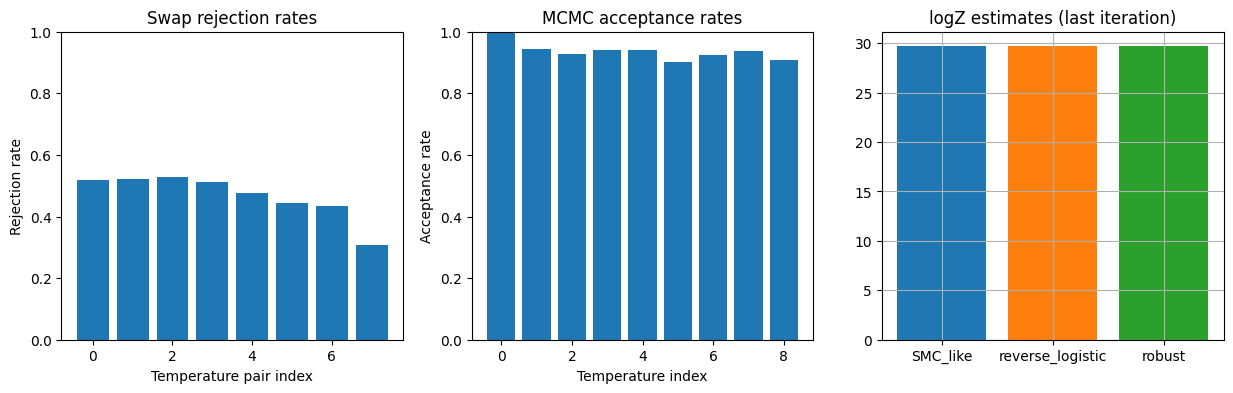

In [8]:
last_diag = diagnostics[-1]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Swap rejection rates
axes[0].bar(range(len(temperatures) - 1), last_diag['swap_rejection_rates'])
axes[0].set_xlabel('Temperature pair index')
axes[0].set_ylabel('Rejection rate')
axes[0].set_title('Swap rejection rates')
axes[0].set_ylim(0, 1)

# MCMC acceptance rates
axes[1].bar(range(len(temperatures)), last_diag['mcmc_acc_rates'])
axes[1].set_xlabel('Temperature index')
axes[1].set_ylabel('Acceptance rate')
axes[1].set_title('MCMC acceptance rates')
axes[1].set_ylim(0, 1)

# logZ estimates as bar plot
for name in ['logZ_SMC_like', 'logZ_reverse_logistic', 'logZ_robust']:
    if name in last_diag:
        axes[2].bar(name.replace('logZ_', ''), last_diag[name])
axes[2].set_title('logZ estimates (last iteration)')
axes[2].grid(True)

print("\nlogZ estimates at last iteration:")
for name in ['logZ_SMC_like', 'logZ_reverse_logistic', 'logZ_robust']:
    if name in last_diag:
        print(f"  {name}: {last_diag[name]:.4f}")

## Transforming back to 8D particle positions

The sampler works in the 6D reduced space. To recover physical particle
positions, we apply the inverse map $x_{8D} = Q\, z_{6D}$, then reshape
each 8-vector into 4 particles in 2D.

In [9]:
# Extract particles at the final temperature (t=1)
samples_6d = pt_state.X.position[pt_state.Z[-1]]  # shape (n_particles, 6)

# Map back to 8D and reshape to (n_particles, 4, 2)
samples_8d = samples_6d @ Q.T  # shape (n_particles, 8)
particles = samples_8d.reshape(-1, 4, 2)

# Verify COM is zero
com = particles.mean(axis=1)  # shape (n_particles, 2)
print(f"Max |COM|: {np.max(np.abs(com)):.2e} (should be ~0)")
print(f"Sample shape: {particles.shape} -- (n_particles, 4 particles, 2D)")

Max |COM|: 3.89e-16 (should be ~0)
Sample shape: (100000, 4, 2) -- (n_particles, 4 particles, 2D)


Text(0.5, 1.0, 'Energy distribution of samples')

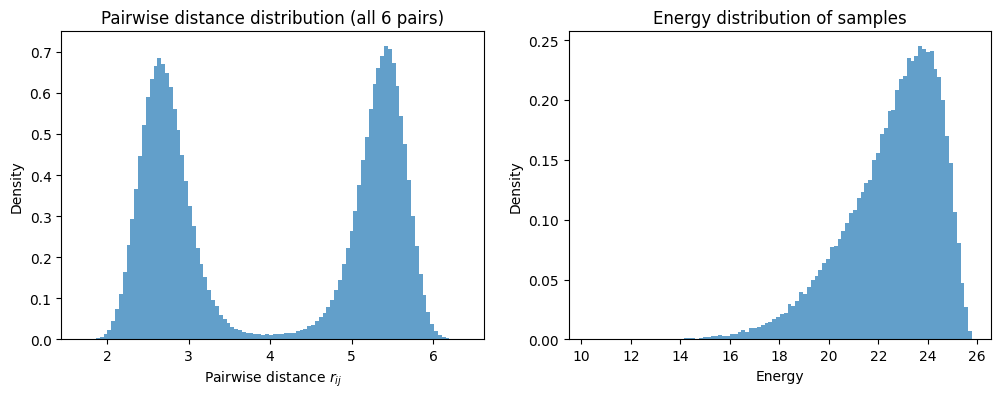

In [10]:
# Compute all pairwise distances for each sample
i_idx, j_idx = np.triu_indices(4, k=1)  # 6 unique pairs
diffs = particles[:, i_idx] - particles[:, j_idx]  # (n_particles, 6, 2)
distances = np.sqrt(np.sum(diffs**2, axis=-1))     # (n_particles, 6)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pairwise distance histogram (all 6 pairs pooled)
axes[0].hist(np.array(distances).ravel(), bins=100, density=True, alpha=0.7)
axes[0].set_xlabel('Pairwise distance $r_{ij}$')
axes[0].set_ylabel('Density')
axes[0].set_title('Pairwise distance distribution (all 6 pairs)')

# histogram of energies stored in particles
energies = dw4(np.array(particles.reshape(-1, 8)))
# plot histogram of energies
axes[1].hist(np.array(energies), bins=100, density=True, alpha=0.7)
axes[1].set_xlabel('Energy')
axes[1].set_ylabel('Density')
axes[1].set_title('Energy distribution of samples')

## Comparison with reference samples

We compare our PT samples against the DEM reference test split
(`data/test_split_DW4.npy`). The reference samples are in full 8D coordinates
and need to be centered (COM removed) before comparison since our sampler
works in the COM=0 subspace.

In [11]:
# Load reference samples
ref_samples_8d = np.load(Path().resolve().parent / "data" / "test_split_DW4.npy")
print(f"Reference samples: {ref_samples_8d.shape}")

# Center reference samples (remove COM)
ref_particles = ref_samples_8d.reshape(-1, 4, 2)
ref_com = ref_particles.mean(axis=1, keepdims=True)
ref_particles = ref_particles - ref_com
ref_samples_8d = ref_particles.reshape(-1, 8)

# Pairwise distances for reference
ref_diffs = ref_particles[:, i_idx] - ref_particles[:, j_idx]
ref_distances = np.sqrt(np.sum(ref_diffs**2, axis=-1))

# Energies for reference
ref_energies = dw4(ref_samples_8d)

Reference samples: (10000, 8)


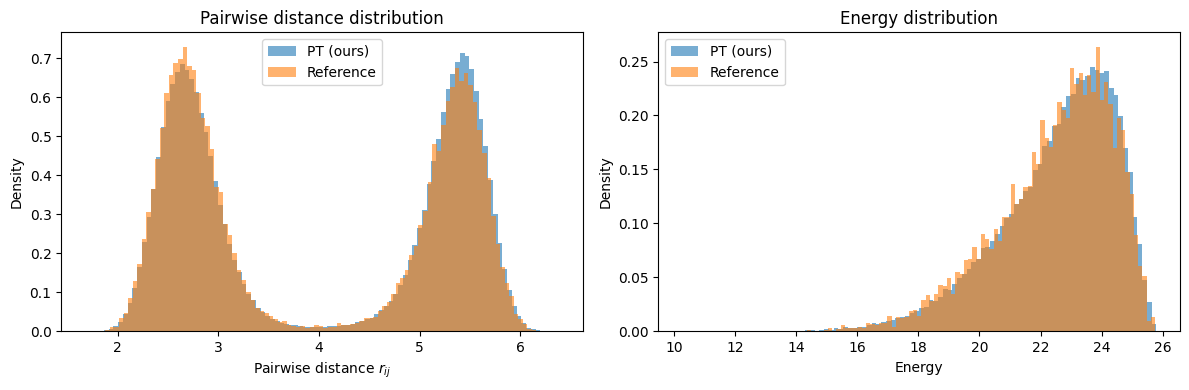

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pairwise distance comparison
axes[0].hist(np.array(distances).ravel(), bins=100, density=True, alpha=0.6, label='PT (ours)')
axes[0].hist(ref_distances.ravel(), bins=100, density=True, alpha=0.6, label='Reference')
axes[0].set_xlabel('Pairwise distance $r_{ij}$')
axes[0].set_ylabel('Density')
axes[0].set_title('Pairwise distance distribution')
axes[0].legend()

# Energy comparison
axes[1].hist(np.array(energies), bins=100, density=True, alpha=0.6, label='PT (ours)')
axes[1].hist(np.array(ref_energies), bins=100, density=True, alpha=0.6, label='Reference')
axes[1].set_xlabel('Energy')
axes[1].set_ylabel('Density')
axes[1].set_title('Energy distribution')
axes[1].legend()

fig.tight_layout()
plt.show()